Step 1: Title and imports

In [3]:

# Traffic Flow Prediction Using Linear Regression and Decision Tree Classification
#Varada K N | M1 AI | 221TCS011

#Dataset: Metro Interstate Traffic Volume (UCI Machine Learning Repository)
#- Linear Regression: predicts traffic volume (numerical)
#- Decision Tree Classifier: classifies traffic as Low / Moderate / High

# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# Step 2: Dataset Collection
The dataset contains hourly westbound I-94 traffic volume (2012-2018) with weather and date-time information.



In [4]:
import urllib.request, zipfile, io, glob

url = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"
try:
    raw = urllib.request.urlopen(url).read()
    zipfile.ZipFile(io.BytesIO(raw)).extractall("data")
    path = [f for f in glob.glob("data/*") if "raffic" in f][0]
    df = pd.read_csv(path)
    print("Loaded:", path)
except Exception as e:
    print("Download failed:", e)
    from google.colab import files
    up = files.upload()          # upload the CSV manually
    df = pd.read_csv(list(up.keys())[0])

df.head()

Loaded: data/Metro_Interstate_Traffic_Volume.csv.gz


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## Step 3: Data Inspection
Checking structure, data types, missing values, duplicates and invalid values.

In [5]:
print("Shape:", df.shape)
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate timestamps:", df.duplicated(subset="date_time").sum())
print("Rows with temp == 0 K:", (df["temp"] == 0).sum())
print("Max rain_1h:", df["rain_1h"].max())
print(df["holiday"].value_counts().head())
df.describe()

Shape: (48204, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB

Missing values:
 holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volu

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


## Step 4: Data Preprocessing
- Convert date_time to datetime and sort chronologically
- Remove invalid date-times, missing targets and duplicates
- Mark invalid values (temp <= 0 K, impossible rainfall) as missing; they are imputed later using training medians
- Replace the holiday value "None" with "No Holiday"

In [6]:
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
df = df.dropna(subset=["date_time", "traffic_volume"])
df = df.drop_duplicates(subset="date_time", keep="first")
df = df.sort_values("date_time").reset_index(drop=True)

df.loc[df["temp"] <= 0, "temp"] = np.nan
df.loc[df["rain_1h"] > 500, "rain_1h"] = np.nan

df["holiday"] = df["holiday"].replace("None", "No Holiday").fillna("No Holiday")

for c in ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Shape after cleaning:", df.shape)
print(df.isnull().sum())

Shape after cleaning: (40575, 9)
holiday                 0
temp                   10
rain_1h                 1
snow_1h                 0
clouds_all              0
weather_main            0
weather_description     0
date_time               0
traffic_volume          0
dtype: int64


## Step 5: Feature Engineering
Extract hour, month, day of week, weekend and holiday indicators. Hour and month are also encoded with sine/cosine so 23:00 and 00:00 are treated as neighbours.

In [7]:
df["hour"]        = df["date_time"].dt.hour
df["month"]       = df["date_time"].dt.month
df["day_of_week"] = df["date_time"].dt.dayofweek
df["is_weekend"]  = (df["day_of_week"] >= 5).astype(int)
df["is_holiday"]  = (df["holiday"] != "No Holiday").astype(int)

df["hour_sin"]  = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]  = np.cos(2 * np.pi * df["hour"] / 24)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

df[["date_time", "hour", "month", "day_of_week", "is_weekend", "is_holiday", "traffic_volume"]].head()

,date_time,hour,month,day_of_week,is_weekend,is_holiday,traffic_volume
0,2012-10-02 09:00:00,9,10,1,0,0,5545
1,2012-10-02 10:00:00,10,10,1,0,0,4516
2,2012-10-02 11:00:00,11,10,1,0,0,4767
3,2012-10-02 12:00:00,12,10,1,0,0,5026
4,2012-10-02 13:00:00,13,10,1,0,0,4918


## Step 6: Exploratory Data Analysis
Graphs showing how traffic volume changes by hour, day and weather.

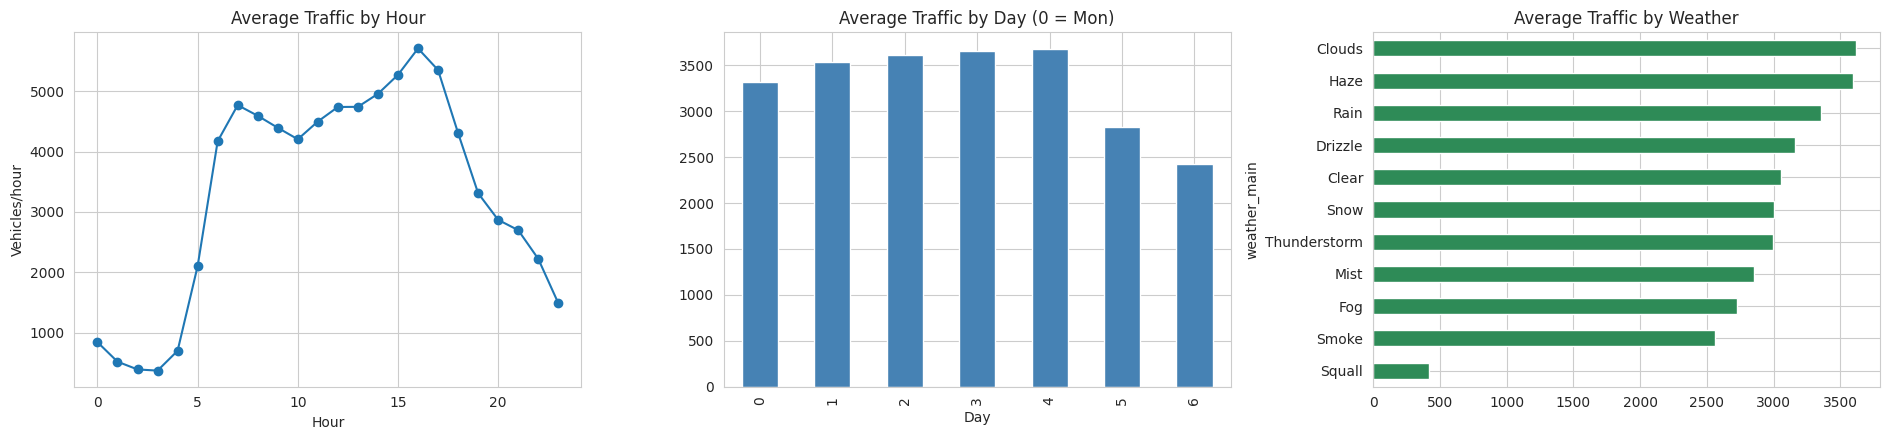

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))

df.groupby("hour")["traffic_volume"].mean().plot(ax=ax[0], marker="o")
ax[0].set(title="Average Traffic by Hour", xlabel="Hour", ylabel="Vehicles/hour")

df.groupby("day_of_week")["traffic_volume"].mean().plot(kind="bar", ax=ax[1], color="steelblue")
ax[1].set(title="Average Traffic by Day (0 = Mon)", xlabel="Day")

df.groupby("weather_main")["traffic_volume"].mean().sort_values().plot(kind="barh", ax=ax[2], color="seagreen")
ax[2].set(title="Average Traffic by Weather")

plt.tight_layout()
plt.savefig("eda_patterns.png", dpi=200)
plt.show()

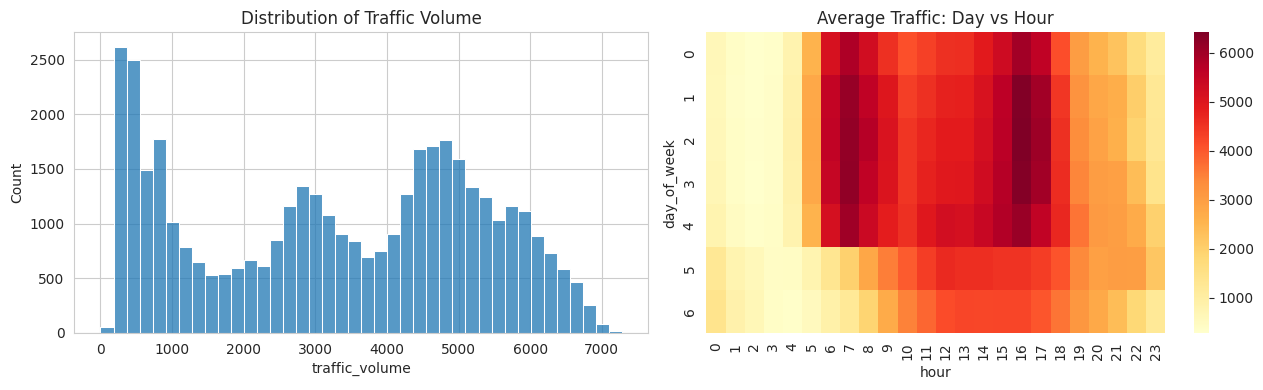

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["traffic_volume"], bins=40, ax=ax[0])
ax[0].set_title("Distribution of Traffic Volume")
sns.heatmap(df.pivot_table(values="traffic_volume", index="day_of_week",
                           columns="hour", aggfunc="mean"), cmap="YlOrRd", ax=ax[1])
ax[1].set_title("Average Traffic: Day vs Hour")
plt.tight_layout()
plt.savefig("eda_heatmap.png", dpi=200)
plt.show()

## Step 7: Chronological Train/Test Split
The earlier 80% of the data is used for training and the later 20% for testing, which better represents predicting future traffic. traffic_volume is excluded from the inputs to prevent target leakage.

In [10]:
features_cat = ["holiday", "weather_main", "weather_description"]
features_num = ["temp", "rain_1h", "snow_1h", "clouds_all",
                "hour", "month", "day_of_week", "is_weekend", "is_holiday",
                "hour_sin", "hour_cos", "month_sin", "month_cos"]

X = df[features_num + features_cat]
y = df["traffic_volume"]

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.shape, df["date_time"].iloc[0], "to", df["date_time"].iloc[split-1])
print("Test :", X_test.shape, df["date_time"].iloc[split], "to", df["date_time"].iloc[-1])

Train: (32460, 16) 2012-10-02 09:00:00 to 2017-10-26 17:00:00
Test : (8115, 16) 2017-10-26 18:00:00 to 2018-09-30 23:00:00


## Step 8: Preprocessing Pipeline
- Numeric features: median imputation
- Categorical features: most-frequent imputation + one-hot encoding
- No scaling (not needed for Linear Regression or Decision Tree)
All parameters are learned from the training data only, which avoids information leakage.

In [12]:
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), features_num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), features_cat)
])
print("Pipeline ready")

Pipeline ready


## Step 9: Linear Regression (Traffic Volume)
Evaluated with MAE, RMSE and R2.

In [13]:
lr_model = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.4f}")

MAE  : 810.65
RMSE : 1035.84
R2   : 0.7235


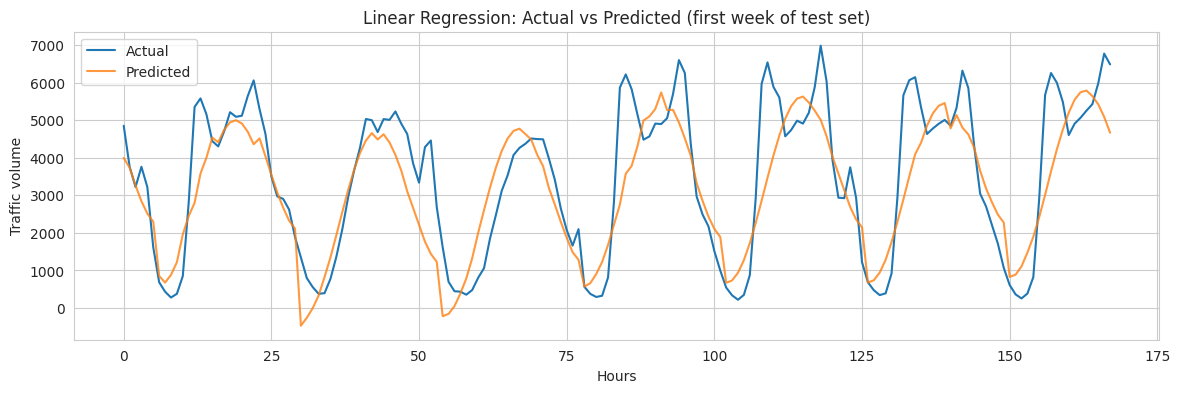

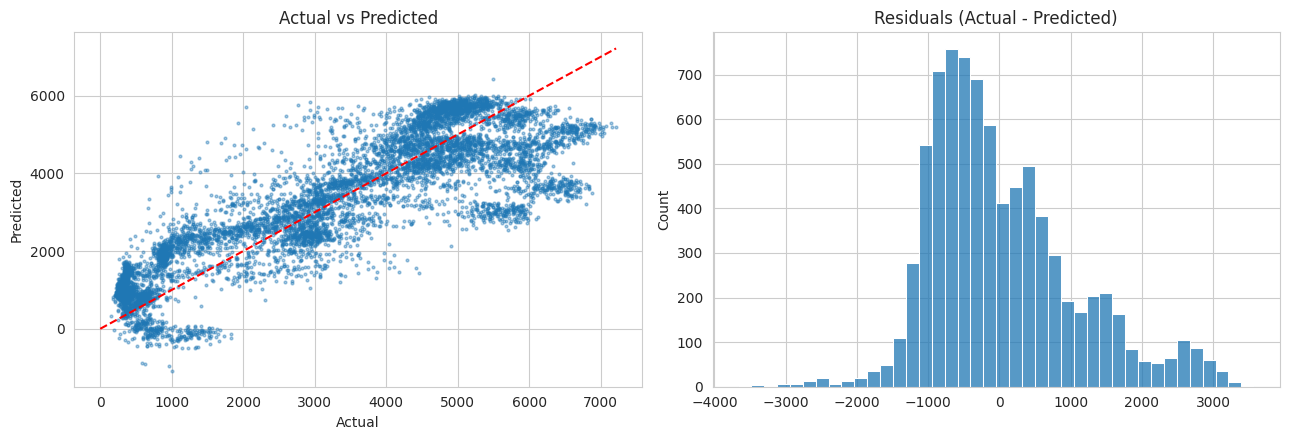

In [14]:
n = 24 * 7
plt.figure(figsize=(14, 4))
plt.plot(y_test.values[:n], label="Actual")
plt.plot(y_pred[:n], label="Predicted", alpha=0.8)
plt.title("Linear Regression: Actual vs Predicted (first week of test set)")
plt.xlabel("Hours"); plt.ylabel("Traffic volume"); plt.legend()
plt.savefig("lr_week.png", dpi=200)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, y_pred, s=4, alpha=0.4)
lim = [0, max(y_test.max(), y_pred.max())]
ax[0].plot(lim, lim, "r--")
ax[0].set(xlabel="Actual", ylabel="Predicted", title="Actual vs Predicted")
sns.histplot(y_test.values - y_pred, bins=40, ax=ax[1])
ax[1].set(title="Residuals (Actual - Predicted)")
plt.tight_layout()
plt.savefig("lr_scatter_residuals.png", dpi=200)
plt.show()

## Step 10: Traffic Category Generation
Two thresholds (33rd and 67th percentiles) are calculated from the training data only and applied to both sets.
Low < threshold 1 <= Moderate < threshold 2 <= High

In [15]:
t1, t2 = y_train.quantile([1/3, 2/3])
print(f"Low < {t1:.0f} | Moderate {t1:.0f}-{t2:.0f} | High >= {t2:.0f}")

def to_level(v):
    return np.where(v < t1, "Low", np.where(v < t2, "Moderate", "High"))

yc_train = pd.Series(to_level(y_train.values), index=y_train.index)
yc_test  = pd.Series(to_level(y_test.values),  index=y_test.index)

print(yc_train.value_counts(normalize=True).round(3))
print(yc_test.value_counts(normalize=True).round(3))

Low < 2257 | Moderate 2257-4593 | High >= 4593
High        0.333
Moderate    0.333
Low         0.333
Name: proportion, dtype: float64
High        0.339
Moderate    0.335
Low         0.327
Name: proportion, dtype: float64


## Step 11: Decision Tree Classification
Depth is limited (max_depth=10, min_samples_leaf=5) to reduce overfitting. Evaluated with accuracy, precision, recall, F1-score and a confusion matrix.

In [16]:
dt_model = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=42))
])
dt_model.fit(X_train, yc_train)
yc_pred = dt_model.predict(X_test)

labels = ["Low", "Moderate", "High"]
print("Accuracy:", round(accuracy_score(yc_test, yc_pred), 4))
print(classification_report(yc_test, yc_pred, labels=labels, digits=4))

Accuracy: 0.8876
              precision    recall  f1-score   support

         Low     0.9434    0.9434    0.9434      2652
    Moderate     0.8497    0.8203    0.8348      2716
        High     0.8705    0.9003    0.8851      2747

    accuracy                         0.8876      8115
   macro avg     0.8879    0.8880    0.8878      8115
weighted avg     0.8874    0.8876    0.8873      8115



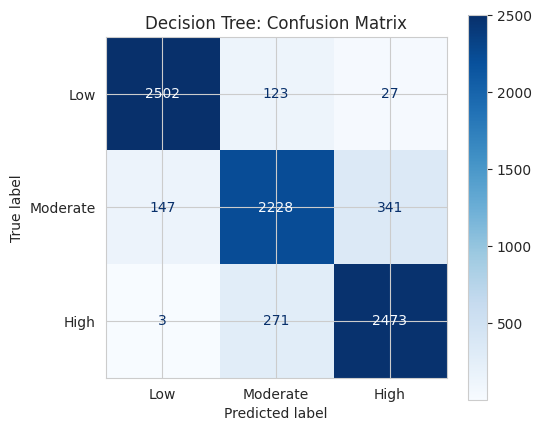

In [17]:
cm = confusion_matrix(yc_test, yc_pred, labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Decision Tree: Confusion Matrix")
plt.savefig("dt_confusion_matrix.png", dpi=200)
plt.show()

## Step 12: Additional Analysis
Effect of tree depth (underfitting vs overfitting) and feature importance.

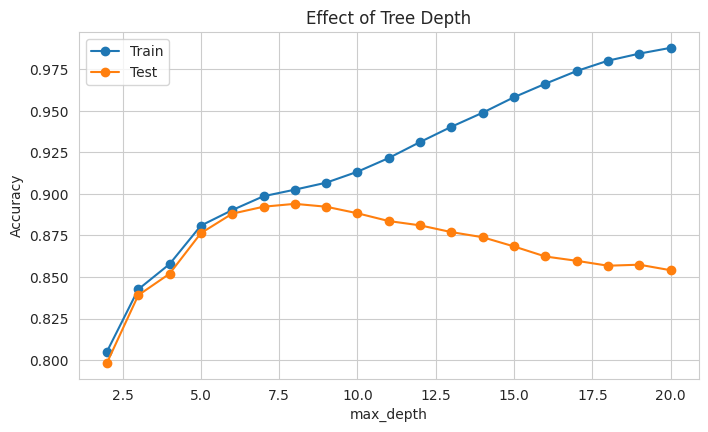

In [18]:
depths = range(2, 21)
tr, te = [], []
for d in depths:
    m = Pipeline([("prep", preprocessor),
                  ("model", DecisionTreeClassifier(max_depth=d, random_state=42))])
    m.fit(X_train, yc_train)
    tr.append(m.score(X_train, yc_train)); te.append(m.score(X_test, yc_test))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, tr, marker="o", label="Train")
plt.plot(depths, te, marker="o", label="Test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Effect of Tree Depth")
plt.savefig("dt_depth.png", dpi=200)
plt.show()

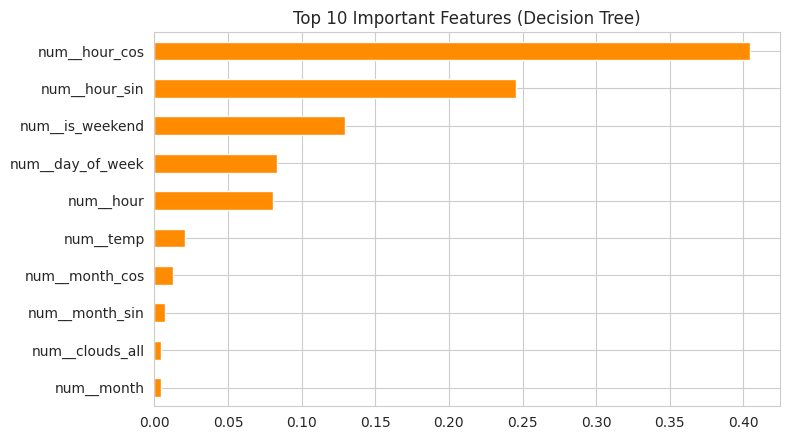

In [19]:
names = dt_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(dt_model.named_steps["model"].feature_importances_, index=names)
imp.sort_values(ascending=False).head(10).sort_values().plot(kind="barh", color="darkorange", figsize=(8, 4.5))
plt.title("Top 10 Important Features (Decision Tree)")
plt.tight_layout()
plt.savefig("dt_feature_importance.png", dpi=200)
plt.show()

##Step 13: Result summary

In [20]:
print("=== Linear Regression ===")
print(pd.DataFrame({"MAE": [mae], "RMSE": [rmse], "R2": [r2]}).round(3).to_string(index=False))

print("\n=== Decision Tree Classifier ===")
print(pd.DataFrame(classification_report(yc_test, yc_pred, output_dict=True)).T.round(3))

=== Linear Regression ===
    MAE     RMSE    R2
810.647 1035.844 0.724

=== Decision Tree Classifier ===
              precision  recall  f1-score   support
High              0.870   0.900     0.885  2747.000
Low               0.943   0.943     0.943  2652.000
Moderate          0.850   0.820     0.835  2716.000
accuracy          0.888   0.888     0.888     0.888
macro avg         0.888   0.888     0.888  8115.000
weighted avg      0.887   0.888     0.887  8115.000


## Step 15: Predict Traffic for a Moment (User Input)
Enter a date, time and weather. Linear Regression predicts the traffic volume and the
Decision Tree predicts the traffic level. The graph shows the same day hour by hour.

=== PREDICT TRAFFIC FOR A MOMENT ===
Date (YYYY-MM-DD) [2026-10-18]: 2026-10-18
Time (HH:MM, 24-hour) [08:00]: 8:00
Temperature in °C [10]: 10
Rain in last hour (mm) [0]: 0
Snow in last hour (mm) [0]: 0
Cloud cover (%) [40]: 40
Weather options: Clear, Clouds, Drizzle, Fog, Haze, Mist, Rain, Smoke, Snow, Squall, Thunderstorm
Weather [Clouds]: clouds
Weather detail options: overcast clouds, broken clouds, scattered clouds, few clouds
Weather detail [overcast clouds]: clouds
  Not a valid option, try again.
Weather detail [overcast clouds]: broken clouds
Is it a holiday? (yes/no) [no]: no

Date/time        : Sunday, 18 Oct 2026, 08:00
Predicted volume : 3,172 vehicles/hour   (Linear Regression)
Predicted level  : Low   (Decision Tree)
Level ranges     : Low < 2257 | Moderate 2257-4593 | High >= 4593


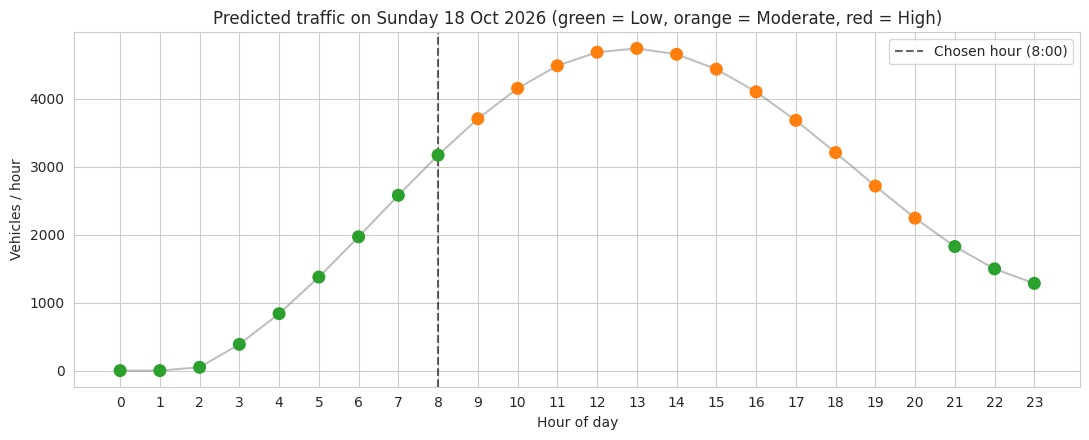

,hour,volume,level
0,0,0,Low
1,1,0,Low
2,2,49,Low
3,3,387,Low
4,4,838,Low
5,5,1377,Low
6,6,1970,Low
7,7,2581,Low
8,8,3172,Low
9,9,3708,Moderate


In [37]:
# ===== PREDICT A MOMENT (backend only, runs in Colab) =====
# Needs the earlier notebook steps to be run first: df, lr_model, dt_model, t1, t2

def predict_moment(when, temp_c=10, rain_1h=0, snow_1h=0, clouds_all=40,
                   weather_main="Clouds", weather_description=None, holiday="No Holiday"):
    """Return (predicted_volume, predicted_level) for one date/time and weather."""
    when = pd.to_datetime(when)
    if weather_description is None:   # most common detail for this weather in the dataset
        weather_description = df.loc[df["weather_main"] == weather_main,
                                      "weather_description"].value_counts().index[0]
    row = pd.DataFrame([{
        "temp": temp_c + 273.15,                     # dataset uses Kelvin
        "rain_1h": rain_1h, "snow_1h": snow_1h, "clouds_all": clouds_all,
        "hour": when.hour, "month": when.month, "day_of_week": when.dayofweek,
        "is_weekend": int(when.dayofweek >= 5), "is_holiday": int(holiday != "No Holiday"),
        "hour_sin": np.sin(2 * np.pi * when.hour / 24), "hour_cos": np.cos(2 * np.pi * when.hour / 24),
        "month_sin": np.sin(2 * np.pi * when.month / 12), "month_cos": np.cos(2 * np.pi * when.month / 12),
        "holiday": holiday, "weather_main": weather_main,
        "weather_description": weather_description,
    }])
    volume = max(0, int(round(lr_model.predict(row)[0])))     # Linear Regression
    level = dt_model.predict(row)[0]                          # Decision Tree Classifier
    return volume, level


def ask(prompt, default, cast=str):
    v = input(f"{prompt} [{default}]: ").strip()
    return cast(v) if v else cast(default)

def ask_choice(prompt, options, default):
    print(f"{prompt} options: {', '.join(options)}")
    while True:
        v = input(f"{prompt} [{default}]: ").strip() or default
        hit = [o for o in options if o.lower() == v.lower()]
        if hit:
            return hit[0]
        print("  Not a valid option, try again.")


print("=== PREDICT TRAFFIC FOR A MOMENT ===")
tomorrow = (pd.Timestamp.now() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

while True:
    date_str = ask("Date (YYYY-MM-DD)", tomorrow)
    time_str = ask("Time (HH:MM, 24-hour)", "08:00")
    try:
        when = pd.to_datetime(f"{date_str} {time_str}")
        break
    except Exception:
        print("  Invalid date or time, try again.")

temp_c  = ask("Temperature in °C", 10, float)
rain    = ask("Rain in last hour (mm)", 0, float)
snow    = ask("Snow in last hour (mm)", 0, float)
clouds  = ask("Cloud cover (%)", 40, int)
weather = ask_choice("Weather", sorted(df["weather_main"].unique()), "Clouds")
descs   = df.loc[df["weather_main"] == weather, "weather_description"].value_counts().index.tolist()
desc    = ask_choice("Weather detail", descs, descs[0])
holiday = "No Holiday"
if ask("Is it a holiday? (yes/no)", "no").lower().startswith("y"):
    hols = [h for h in df["holiday"].unique() if h != "No Holiday"]
    holiday = ask_choice("Holiday", hols, hols[0])

# ---- prediction ----
volume, level = predict_moment(when, temp_c, rain, snow, clouds, weather, desc, holiday)
print("\n" + "=" * 45)
print(f"Date/time        : {when:%A, %d %b %Y, %H:%M}")
print(f"Predicted volume : {volume:,} vehicles/hour   (Linear Regression)")
print(f"Predicted level  : {level}   (Decision Tree)")
print(f"Level ranges     : Low < {t1:.0f} | Moderate {t1:.0f}-{t2:.0f} | High >= {t2:.0f}")
print("=" * 45)

# ---- same day, hour by hour, with the same weather ----
day = pd.Timestamp(when.date())
hours = [(h, *predict_moment(day + pd.Timedelta(hours=h), temp_c, rain, snow, clouds,
                             weather, desc, holiday)) for h in range(24)]
day_df = pd.DataFrame(hours, columns=["hour", "volume", "level"])

colors = {"Low": "tab:green", "Moderate": "tab:orange", "High": "tab:red"}
plt.figure(figsize=(11, 4.5))
plt.plot(day_df["hour"], day_df["volume"], color="gray", alpha=0.5)
plt.scatter(day_df["hour"], day_df["volume"], c=day_df["level"].map(colors), s=70, zorder=3)
plt.axvline(when.hour, color="black", linestyle="--", alpha=0.6, label=f"Chosen hour ({when.hour}:00)")
plt.xticks(range(24)); plt.xlabel("Hour of day"); plt.ylabel("Vehicles / hour")
plt.title(f"Predicted traffic on {when:%A %d %b %Y} (green = Low, orange = Moderate, red = High)")
plt.legend(); plt.tight_layout()
plt.savefig("predicted_day.png", dpi=200)
plt.show()
day_df

## Step 17: Predicting Traffic for the Next 10 Days Using a Weather Forecast
Hourly weather forecasts (Open-Meteo API, up to 16 days ahead) for the I-94 Minneapolis-St. Paul area
are converted to the dataset's format and passed to both models. Results are shown hourly and as a daily summary.

In [22]:
import requests

LAT, LON = 44.95, -93.10          # I-94, Minneapolis-St. Paul (location of the dataset)
TZ = "America/Chicago"           # dataset timestamps are in local time

def get_weather_forecast(days):
    r = requests.get("https://api.open-meteo.com/v1/forecast", params={
        "latitude": LAT, "longitude": LON,
        "hourly": "temperature_2m,precipitation,snowfall,cloud_cover,weather_code",
        "forecast_days": days, "timezone": TZ}, timeout=30)
    r.raise_for_status()
    w = pd.DataFrame(r.json()["hourly"])
    w["time"] = pd.to_datetime(w["time"])
    return w

def wmo_to_main(code):
    if code == 0:                                return "Clear"
    if code in (1, 2, 3):                        return "Clouds"
    if code in (45, 48):                         return "Fog"
    if code in (51, 53, 55, 56, 57):             return "Drizzle"
    if code in (61, 63, 65, 66, 67, 80, 81, 82): return "Rain"
    if code in (71, 73, 75, 77, 85, 86):         return "Snow"
    if code in (95, 96, 99):                     return "Thunderstorm"
    return "Clouds"

common_desc = df.groupby("weather_main")["weather_description"] \
                .agg(lambda s: s.value_counts().index[0]).to_dict()
known_main = set(df["weather_main"].unique())

def forecast_traffic_range(days=10):
    """Predict hourly traffic for each day from tomorrow to `days` days ahead (max 15)."""
    w = get_weather_forecast(days + 1)
    start = pd.Timestamp.now(tz=TZ).normalize().tz_localize(None) + pd.Timedelta(days=1)
    end = start + pd.Timedelta(days=days)
    w = w[(w["time"] >= start) & (w["time"] < end)].reset_index(drop=True)

    t = w["time"]
    main = w["weather_code"].apply(wmo_to_main).apply(lambda m: m if m in known_main else "Clouds")

    X_new = pd.DataFrame({
        "temp": w["temperature_2m"] + 273.15,
        "rain_1h": w["precipitation"],
        "snow_1h": w["snowfall"],
        "clouds_all": w["cloud_cover"],
        "hour": t.dt.hour, "month": t.dt.month, "day_of_week": t.dt.dayofweek,
        "is_weekend": (t.dt.dayofweek >= 5).astype(int),
        "is_holiday": 0,
        "hour_sin": np.sin(2 * np.pi * t.dt.hour / 24),
        "hour_cos": np.cos(2 * np.pi * t.dt.hour / 24),
        "month_sin": np.sin(2 * np.pi * t.dt.month / 12),
        "month_cos": np.cos(2 * np.pi * t.dt.month / 12),
        "holiday": "No Holiday",
        "weather_main": main,
        "weather_description": main.map(common_desc),
    })

    return pd.DataFrame({
        "time": t,
        "date": t.dt.date,
        "temp_c": w["temperature_2m"],
        "rain_mm": w["precipitation"],
        "snow_cm": w["snowfall"],
        "weather": main,
        "volume": np.maximum(0, lr_model.predict(X_new)).round(0).astype(int),
        "level": dt_model.predict(X_new),
    })

N_DAYS = 10
fc = forecast_traffic_range(N_DAYS)
print("Hourly rows:", len(fc), "| From", fc["time"].min(), "to", fc["time"].max())
fc.head(24)

Hourly rows: 240 | From 2026-10-18 00:00:00 to 2026-10-27 23:00:00


,time,date,temp_c,rain_mm,snow_cm,weather,volume,level
0,2026-10-18 00:00:00,2026-10-18,6.2,0.0,0.0,Clear,0,Low
1,2026-10-18 01:00:00,2026-10-18,6.1,0.0,0.0,Clear,0,Low
2,2026-10-18 02:00:00,2026-10-18,6.1,0.0,0.0,Clear,62,Low
3,2026-10-18 03:00:00,2026-10-18,5.9,0.0,0.0,Clear,400,Low
4,2026-10-18 04:00:00,2026-10-18,5.8,0.0,0.0,Clear,851,Low
5,2026-10-18 05:00:00,2026-10-18,5.6,0.0,0.0,Clear,1379,Low
6,2026-10-18 06:00:00,2026-10-18,5.4,0.0,0.0,Clouds,1996,Low
7,2026-10-18 07:00:00,2026-10-18,5.2,0.0,0.0,Clouds,2610,Low
8,2026-10-18 08:00:00,2026-10-18,5.0,0.0,0.0,Clouds,3230,Moderate
9,2026-10-18 09:00:00,2026-10-18,7.3,0.0,0.0,Clouds,3749,Moderate


In [23]:
daily = fc.groupby("date").agg(
    day=("time", lambda s: s.iloc[0].day_name()),
    avg_temp_c=("temp_c", "mean"),
    total_rain_mm=("rain_mm", "sum"),
    total_snow_cm=("snow_cm", "sum"),
    main_weather=("weather", lambda s: s.value_counts().index[0]),
    avg_volume=("volume", "mean"),
    peak_volume=("volume", "max"),
    peak_hour=("time", lambda s: s[fc.loc[s.index, "volume"].idxmax()].strftime("%H:%M")),
    high_traffic_hours=("level", lambda s: (s == "High").sum()),
).round(1)
daily

,day,avg_temp_c,total_rain_mm,total_snow_cm,main_weather,avg_volume,peak_volume,peak_hour,high_traffic_hours
date,,,,,,,,,
2026-10-18,Sunday,10.7,0.0,0.0,Clear,2607.1,4786,13:00,0
2026-10-19,Monday,13.2,0.0,0.0,Clear,3403.3,5636,13:00,10
2026-10-20,Tuesday,13.7,0.0,0.0,Clear,3448.9,5640,13:00,12
2026-10-21,Wednesday,15.5,0.0,0.0,Clouds,3542.0,5712,13:00,13
2026-10-22,Thursday,17.3,0.0,0.0,Clouds,3601.2,5761,13:00,13
2026-10-23,Friday,18.6,0.0,0.0,Clouds,3650.8,5842,13:00,13
2026-10-24,Saturday,15.6,0.0,0.0,Clouds,2579.7,4721,13:00,2
2026-10-25,Sunday,8.9,0.0,0.0,Clouds,2615.5,4806,13:00,0
2026-10-26,Monday,9.1,3.0,0.0,Clouds,3403.1,5593,13:00,10


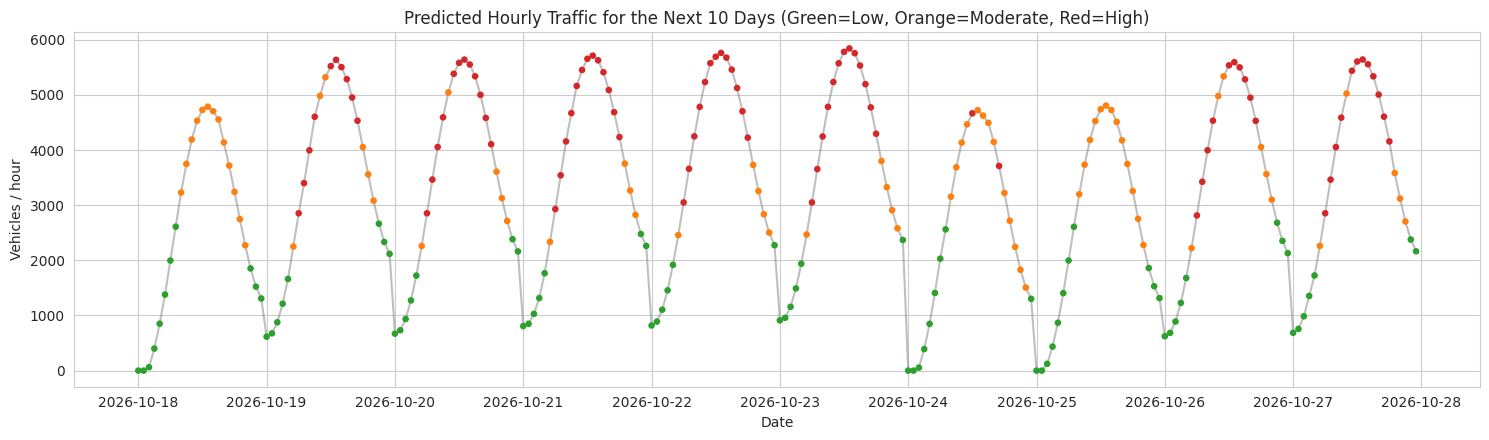

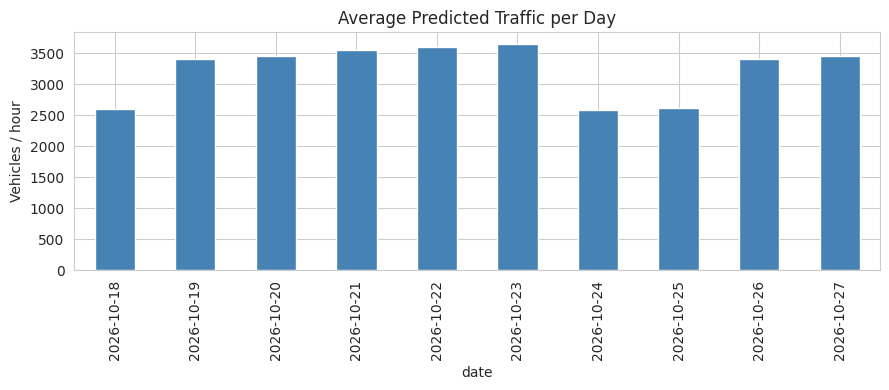

In [24]:
colors = {"Low": "tab:green", "Moderate": "tab:orange", "High": "tab:red"}
plt.figure(figsize=(15, 4.5))
plt.plot(fc["time"], fc["volume"], color="gray", alpha=0.5)
plt.scatter(fc["time"], fc["volume"], c=fc["level"].map(colors), s=14, zorder=3)
plt.title(f"Predicted Hourly Traffic for the Next {N_DAYS} Days (Green=Low, Orange=Moderate, Red=High)")
plt.ylabel("Vehicles / hour"); plt.xlabel("Date")
plt.tight_layout()
plt.savefig("forecast_10_days.png", dpi=200)
plt.show()

plt.figure(figsize=(9, 4))
daily["avg_volume"].plot(kind="bar", color="steelblue")
plt.title("Average Predicted Traffic per Day"); plt.ylabel("Vehicles / hour")
plt.tight_layout()
plt.savefig("forecast_daily_average.png", dpi=200)
plt.show()

In [30]:
!pip install -q -r requirements.txt
!npm install -q -g localtunnel

⠙⠹⠸⠼⠴⠦⠧
changed 22 packages in 957ms
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧

In [35]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [36]:
!pkill -f streamlit
!streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/streamlit_logs.txt &
!./cloudflared tunnel --url http://localhost:8501

2026-10-17T06:14:15Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-17T06:14:15Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-17T06:14:19Z INF +--------------------------------------------------------------------------------------------+
2026-10-17T06:14:19Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-17T06:14:19Z INF |  https://facility-apparently-routers-trance.trycloudfl